# Gemma-2B — Repeatability of Massive Multitask Language Understanding Pro evaluation

**Study design.** Fifteen complete evaluations of the same 12,032 questions were performed on one local serving system. Five concurrent-request settings (8, 32, 64, 128, 256) were tested, with three sequential repetitions per setting.

**Objective.** Quantify repeatability of overall accuracy, evaluation throughput, and individual model responses. This study does not assess equivalence with external leaderboard protocols.

## 1. Experimental configuration

| Component | Configuration |
|---|---|
| Model | `google/gemma-2b`, revision `9cf48e52b224239de00d483ec8eb84fb8d0f3a3a` |
| Evaluation framework | EleutherAI Language Model Evaluation Harness, revision `d6de81643928d653435c431bae19945d41d32520` |
| Dataset | `TIGER-Lab/MMLU-Pro`, revision `b189ec765aa7ed75c8acfea42df31fdae71f97be` |
| Generation | Five demonstrated examples, deterministic decoding requested, temperature zero, maximum 2,048 generated tokens |
| Serving | vLLM `0.33.0`, maximum context length 4,096 tokens; server seed 0 and client seed 1234 |

The framework revision was verified from its installed source directory. The revision recorded in the evaluation results refers to the repository in which the evaluations were launched. The dataset revision is specified in a local task-configuration modification.


In [1]:
# Import the libraries required for data loading and visualization.
import hashlib
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Configure the location and expected structure of the completed experiment.
DATA_DIRECTORY = Path("../results/mmlu-pro-repro")
CONCURRENT_REQUESTS = (8, 32, 64, 128, 256)
REPETITIONS = (1, 2, 3)
QUESTIONS_PER_RUN = 12032
SUBJECTS_PER_RUN = 14

MODEL_REVISION = "9cf48e52b224239de00d483ec8eb84fb8d0f3a3a"
DATASET_REVISION = "b189ec765aa7ed75c8acfea42df31fdae71f97be"

if not DATA_DIRECTORY.is_dir():
  raise FileNotFoundError(f"Evaluation directory not found: {DATA_DIRECTORY.resolve()}")

## 2. Accuracy and evaluation throughput

Overall accuracy is the proportion of correctly answered questions. End-to-end throughput is the number of evaluated questions divided by total elapsed time, including evaluation-framework overhead. Variation between the three repetitions is reported as the **sample standard deviation**; it is distinct from the question-level standard error calculated by the evaluation framework.

In [2]:
# Read one aggregate result and its measured duration for every repetition.
run_records = []

for concurrency in CONCURRENT_REQUESTS:
  for repetition in REPETITIONS:
    run_directory = DATA_DIRECTORY / f"c{concurrency}" / f"run-{repetition}"
    result_files = list((run_directory / "google__gemma-2b").glob("results_*.json"))

    if len(result_files) != 1:
      raise ValueError(f"Expected one aggregate result in {run_directory}")

    with result_files[0].open(encoding="utf-8") as result_file:
      result = json.load(result_file)

    model_arguments = result["config"]["model_args"]
    benchmark_result = result["results"]["mmlu_pro"]
    dataset_config = result["configs"]["mmlu_pro_biology"]
    duration_seconds = float((run_directory / "time.txt").read_text().strip())

    # Fail if a recorded input differs from the intended evaluation configuration.
    assert model_arguments["model"] == "google/gemma-2b"
    assert model_arguments["revision"] == MODEL_REVISION
    assert dataset_config["dataset_kwargs"]["revision"] == DATASET_REVISION
    assert model_arguments["num_concurrent"] == concurrency
    assert result["n-shot"]["mmlu_pro"] == 5
    assert benchmark_result["sample_len"] == QUESTIONS_PER_RUN
    assert sum(name.startswith("mmlu_pro_") for name in result["results"]) == SUBJECTS_PER_RUN

    run_records.append({
      "run": f"c{concurrency}-r{repetition}",
      "concurrency": concurrency,
      "repetition": repetition,
      "accuracy_percent": 100 * benchmark_result["exact_match,custom-extract"],
      "runtime_minutes": duration_seconds / 60,
      "questions_per_second": QUESTIONS_PER_RUN / duration_seconds,
      "directory": run_directory,
    })

runs = pd.DataFrame(run_records)

if len(runs) != len(CONCURRENT_REQUESTS) * len(REPETITIONS):
  raise ValueError("The expected fifteen evaluations were not found")

print(f"Loaded {len(runs)} complete evaluations")

Loaded 15 complete evaluations


In [3]:
# Compare the average and run-to-run variation at each concurrency setting.
summary = (
  runs.groupby("concurrency")
  .agg(
    mean_accuracy=("accuracy_percent", "mean"),
    accuracy_standard_deviation=("accuracy_percent", "std"),
    mean_runtime_minutes=("runtime_minutes", "mean"),
    runtime_standard_deviation=("runtime_minutes", "std"),
    mean_questions_per_second=("questions_per_second", "mean"),
    throughput_standard_deviation=("questions_per_second", "std"),
  )
  .reset_index()
)

display(summary.round(3))

,concurrency,mean_accuracy,accuracy_standard_deviation,mean_runtime_minutes,runtime_standard_deviation,mean_questions_per_second,throughput_standard_deviation
0,8,14.614,0.143,110.822,2.367,1.810,0.039
1,32,14.874,0.067,38.772,1.087,5.175,0.148
2,64,14.788,0.083,30.111,1.381,6.669,0.314
3,128,14.647,0.062,28.194,0.146,7.113,0.037
4,256,14.816,0.019,34.283,0.088,5.849,0.015


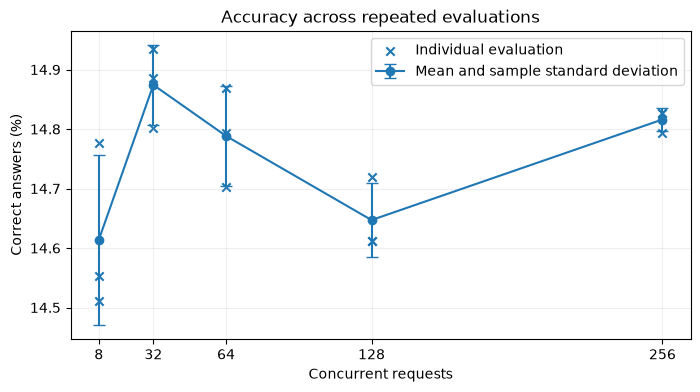

In [4]:
# Plot aggregate accuracy with variation between the three repetitions.
figure, axis = plt.subplots(figsize=(8, 4))

axis.errorbar(
  summary["concurrency"],
  summary["mean_accuracy"],
  yerr=summary["accuracy_standard_deviation"],
  fmt="o-",
  capsize=4,
  label="Mean and sample standard deviation",
)
axis.scatter(runs["concurrency"], runs["accuracy_percent"], marker="x", label="Individual evaluation")

axis.set(
  xlabel="Concurrent requests",
  ylabel="Correct answers (%)",
  title="Accuracy across repeated evaluations",
)
axis.set_xticks(CONCURRENT_REQUESTS)
axis.grid(alpha=0.2)
axis.legend()
plt.show()

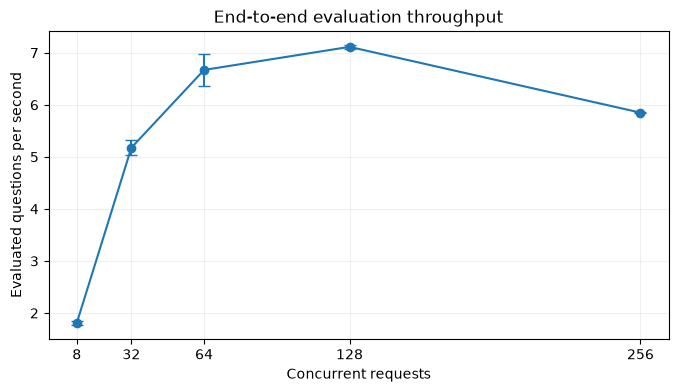

In [5]:
# Plot end-to-end throughput rather than model-generated tokens per second.
figure, axis = plt.subplots(figsize=(8, 4))

axis.errorbar(
  summary["concurrency"],
  summary["mean_questions_per_second"],
  yerr=summary["throughput_standard_deviation"],
  fmt="o-",
  capsize=4,
)

axis.set(
  xlabel="Concurrent requests",
  ylabel="Evaluated questions per second",
  title="End-to-end evaluation throughput",
)
axis.set_xticks(CONCURRENT_REQUESTS)
axis.grid(alpha=0.2)
plt.show()

## 3. Repeatability of individual responses

For each question, the three repetitions at a fixed concurrency are compared. A disagreement is counted when **at least two of the three repetitions differ** in extracted answer, correctness, or generated text. These are question-level three-repetition disagreement rates, not probabilities estimated from individual response pairs.

In [6]:
# Extract only the fields needed for comparison; discard full generated text.
response_records = []

for run in runs.itertuples(index=False):
  sample_files = sorted((run.directory / "google__gemma-2b").glob("samples_mmlu_pro_*.jsonl"))

  if len(sample_files) != SUBJECTS_PER_RUN:
    raise ValueError(f"Expected fourteen subject files for {run.run}")

  for sample_path in sample_files:
    subject = sample_path.name.removeprefix("samples_").rsplit("_", 1)[0]

    with sample_path.open(encoding="utf-8") as sample_file:
      for line in sample_file:
        sample = json.loads(line)
        extracted_answers = sample.get("filtered_resps") or []
        extracted_answer = extracted_answers[0] if extracted_answers else "[missing]"

        generated_responses = sample.get("resps") or []
        generated_text = generated_responses[0] if generated_responses else ""

        if isinstance(generated_text, list):
          generated_text = generated_text[0] if generated_text else ""

        if not isinstance(generated_text, str):
          generated_text = ""

        response_records.append({
          "run": run.run,
          "concurrency": run.concurrency,
          "repetition": run.repetition,
          "question": f"{subject}:{sample['doc_id']}",
          "document_hash": sample["doc_hash"],
          "prompt_hash": sample["prompt_hash"],
          "target_hash": sample["target_hash"],
          "answer": str(extracted_answer),
          "correct": float(sample["exact_match"]),
          "unextractable": re.fullmatch(r"[A-J]", str(extracted_answer)) is None,
          "generated_text_hash": hashlib.sha256(generated_text.encode("utf-8")).hexdigest(),
        })

responses = pd.DataFrame(response_records)

# All runs must contain the same questions and identical evaluation inputs.
if not responses.groupby("run").size().eq(QUESTIONS_PER_RUN).all():
  raise ValueError("Incomplete individual-response records")

if responses.duplicated(["run", "question"]).any():
  raise ValueError("Duplicate question within an evaluation")

if not responses.groupby("question")["run"].nunique().eq(len(runs)).all():
  raise ValueError("Question sets differ between evaluations")

input_changes = responses.groupby("question")[["document_hash", "prompt_hash", "target_hash"]].nunique()

if input_changes.gt(1).any().any():
  raise ValueError("Evaluation inputs differ between repetitions")

# Recalculate the aggregate accuracy directly from individual scores.
recalculated_scores = 100 * responses.groupby("run")["correct"].mean()
reported_scores = runs.set_index("run")["accuracy_percent"]

if not (recalculated_scores - reported_scores).abs().lt(1e-8).all():
  raise ValueError("Individual-response scores do not match aggregate results")

print(f"Validated {len(responses):,} responses to {responses['question'].nunique():,} identical questions")

Validated 180,480 responses to 12,032 identical questions


- **Answer disagreement**:	Percentage of questions for which at least one repetition produced a different extracted answer
- **Correctness disagreement**:	Percentage of questions that were answered correctly in some repetitions and incorrectly in others
- **Text disagreement**:	Percentage of questions for which the complete generated response differed
- **Unextractable answers**:	Percentage of individual responses without a recognizable final answer

In [7]:
# Compare the three independent repetitions for each concurrency setting.
comparison_records = []

for concurrency, group in responses.groupby("concurrency"):

  # Reshape the data so each row represents one question and
  # each column represents one of the three benchmark repetitions.
  # This allows direct comparisons between repetitions.
  answers = group.pivot(index="question", columns="repetition", values="answer")
  correctness = group.pivot(index="question", columns="repetition", values="correct")
  generated_texts = group.pivot(index="question", columns="repetition", values="generated_text_hash")

  # Count distinct values across the three repetitions for every question.
  # More than one distinct value indicates disagreement.
  #
  # The mean of the resulting Boolean values gives the proportion of
  # questions with disagreements. Multiplying by 100 yields a percentage.
  comparison_records.append({
    "concurrency": concurrency,
    "answer_disagreement_percent": 100 * answers.nunique(axis=1).gt(1).mean(),
    "correctness_disagreement_percent": 100 * correctness.nunique(axis=1).gt(1).mean(),
    "text_disagreement_percent": 100 * generated_texts.nunique(axis=1).gt(1).mean(),

    # Percentage of all responses without an extractable final answer.
    "unextractable_percent": 100 * group["unextractable"].mean(),
  })

# Summarize the disagreement measurements for each concurrency setting.
comparison = pd.DataFrame(comparison_records)
display(comparison.round(3))

,concurrency,answer_disagreement_percent,correctness_disagreement_percent,text_disagreement_percent,unextractable_percent
0,8,14.661,3.441,29.812,11.663
1,32,21.518,4.879,42.653,11.580
2,64,22.299,5.269,44.182,11.503
3,128,22.448,5.153,44.332,11.611
4,256,22.149,5.186,43.492,11.400


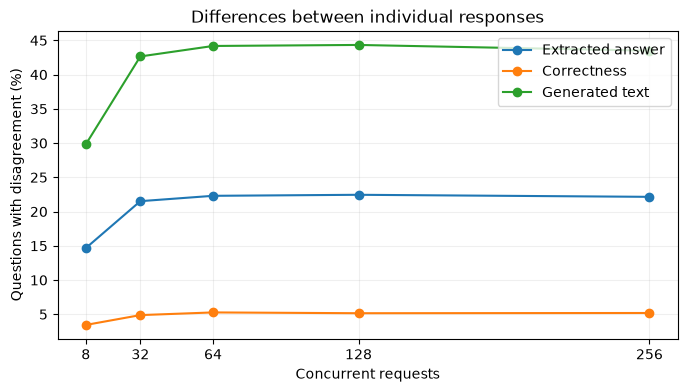

In [8]:
# Visualize disagreement rates across the three repetitions per setting.
figure, axis = plt.subplots(figsize=(8, 4))

for column, label in [
  ("answer_disagreement_percent", "Extracted answer"),
  ("correctness_disagreement_percent", "Correctness"),
  ("text_disagreement_percent", "Generated text"),
]:
  axis.plot(comparison["concurrency"], comparison[column], "o-", label=label)

axis.set(
  xlabel="Concurrent requests",
  ylabel="Questions with disagreement (%)",
  title="Differences between individual responses",
)
axis.set_xticks(CONCURRENT_REQUESTS)
axis.grid(alpha=0.2)
axis.legend()
plt.show()

## 4. Confidence intervals from question resampling

For each concurrency setting, **5,000 bootstrap samples** are drawn from the 12,032 questions, with replacement and a fixed random seed. Each question is resampled **together with its three observed repetitions**. The resulting percentile-based **95% confidence intervals** describe uncertainty from the selection of questions, conditional on the observed runs. The reported estimates use the average accuracy across three runs and the three-run disagreement proportions.

These intervals **do not estimate uncertainty from running the evaluation again**, nor do they establish that concurrency causes a difference. Run-to-run variability remains reported separately as the sample standard deviation (Section 2). The questions form a fixed benchmark rather than a random sample from all possible user requests.


In [9]:
# Estimate uncertainty by resampling questions while keeping all three runs paired.
# Each bootstrap sample contains 12,032 questions sampled with replacement.
BOOTSTRAP_SAMPLES = 5000
BOOTSTRAP_SEED = 12345

random_generator = np.random.default_rng(BOOTSTRAP_SEED)
interval_records = []

for concurrency, group in responses.groupby("concurrency"):
  # Arrange the three answers for each question in the same row.
  answers = group.pivot(index="question", columns="repetition", values="answer")
  correctness = group.pivot(index="question", columns="repetition", values="correct")
  generated_texts = group.pivot(index="question", columns="repetition", values="generated_text_hash")

  # One row contains the average correctness and three disagreement indicators.
  question_values = np.column_stack([
    correctness.to_numpy(dtype=float).mean(axis=1),
    answers.nunique(axis=1).gt(1).to_numpy(dtype=float),
    correctness.nunique(axis=1).gt(1).to_numpy(dtype=float),
    generated_texts.nunique(axis=1).gt(1).to_numpy(dtype=float),
  ])

  bootstrap_results = []
  number_of_questions = len(question_values)

  # Work in small batches to avoid allocating a large index array.
  for start in range(0, BOOTSTRAP_SAMPLES, 100):
    batch_size = min(100, BOOTSTRAP_SAMPLES - start)
    selected_questions = random_generator.integers(
      0, number_of_questions, size=(batch_size, number_of_questions)
    )

    bootstrap_results.append(question_values[selected_questions].mean(axis=1))

  # The middle 95% of the bootstrap estimates form the percentile interval.
  lower, upper = np.percentile(np.concatenate(bootstrap_results), [2.5, 97.5], axis=0)

  interval_records.append({
    "Concurrency": concurrency,
    "Accuracy, 95% interval (%)": f"{100 * lower[0]:.2f}–{100 * upper[0]:.2f}",
    "Answer disagreement, 95% interval (%)": f"{100 * lower[1]:.2f}–{100 * upper[1]:.2f}",
    "Correctness disagreement, 95% interval (%)": f"{100 * lower[2]:.2f}–{100 * upper[2]:.2f}",
    "Text disagreement, 95% interval (%)": f"{100 * lower[3]:.2f}–{100 * upper[3]:.2f}",
  })

confidence_intervals = pd.DataFrame(interval_records)
display(confidence_intervals)


,Concurrency,"Accuracy, 95% interval (%)","Answer disagreement, 95% interval (%)","Correctness disagreement, 95% interval (%)","Text disagreement, 95% interval (%)"
0,8,14.00–15.22,14.01–15.29,3.12–3.77,28.95–30.65
1,32,14.28–15.49,20.81–22.26,4.50–5.27,41.77–43.52
2,64,14.19–15.39,21.55–23.05,4.88–5.66,43.29–45.07
3,128,14.03–15.24,21.73–23.23,4.77–5.55,43.48–45.23
4,256,14.22–15.43,21.43–22.91,4.80–5.59,42.60–44.41


## 5. Findings and limitations

Across the tested settings, mean accuracy remained near **14.6–14.9%**, whereas individual answers differed in a substantial fraction of questions. Thus, similar aggregate scores did not imply identical responses. Approximately **one in nine responses** lacked an answer recognizable by the benchmark's extraction rule; this does not establish a serving failure.

The highest observed end-to-end throughput occurred at **128 concurrent requests**. Throughput declined at 256 requests, indicating that additional concurrency was not beneficial under these measured conditions. This finding does not identify the underlying bottleneck or establish a universal optimum.

The experiment is **exploratory**: each setting has only three sequential repetitions, settings were evaluated in blocks rather than randomized order, and hardware load and temperature were not independently controlled in this analysis. The observed differences therefore do not establish that concurrency itself caused changes in model answers. The documented framework revision was verified separately from the result files.

The percentile confidence intervals quantify uncertainty across benchmark questions, conditional on the observed executions. They do not include additional run-to-run uncertainty.